In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [2]:
project_root = Path.cwd()
if not (project_root / "data" / "supermarket_grocery_sales.csv").is_file():
    project_root = project_root.parent

data_path = project_root / "data" / "supermarket_grocery_sales.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Source dataset not found: {data_path}")

df = pd.read_csv(data_path)
print(df.shape)
df.head()

(9994, 11)


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,11-08-2017,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,11-08-2017,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,06-12-2017,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,10-11-2016,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,10-11-2016,South,2355,0.26,918.45,Tamil Nadu


In [3]:
# Dates: two formats, parsed separately
#   dashes  "11-08-2017" -> day-month-year (assumption)
#   slashes "4/15/2018"  -> month/day/year (certain)
is_slash = df["Order Date"].str.contains("/")

df["Order Date"] = pd.concat([
    pd.to_datetime(df.loc[~is_slash, "Order Date"], format="%d-%m-%Y"),
    pd.to_datetime(df.loc[is_slash,  "Order Date"], format="%m/%d/%Y"),
]).sort_index()

# Constant column
print("Unique states:", df["State"].unique())
df = df.drop(columns="State")

# Quality checks
print("Missing values:\n", df.isna().sum(), sep="")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

Unique states: <ArrowStringArray>
['Tamil Nadu']
Length: 1, dtype: str
Missing values:
Order ID         0
Customer Name    0
Category         0
Sub Category     0
City             0
Order Date       0
Region           0
Sales            0
Discount         0
Profit           0
dtype: int64
Duplicate rows: 0
Duplicate Order IDs: 0
Date range: 2015-01-02 to 2018-12-30


In [4]:
# Margin = Profit / Sales
# DiscountAmt = Sales * Discount
df["Margin"] = df["Profit"] / df["Sales"]
df["DiscountAmt"] = df["Sales"] * df["Discount"]

# Time features
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M")
df["Quarter"] = df["Order Date"].dt.to_period("Q")
df["Weekday"] = df["Order Date"].dt.day_name()

# Summary statistics: only for measured numeric columns
display(df[["Sales", "Discount", "Profit", "Margin", "DiscountAmt"]].describe())

# Time coverage: orders per year, and the date range
print("Orders per year:")
print(df["Year"].value_counts().sort_index())
print("\nDate range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

,Sales,Discount,Profit,Margin,DiscountAmt
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"1,496.60",0.23,374.94,0.25,339.22
std,577.56,0.07,239.93,0.12,176.66
min,500.00,0.10,25.25,0.05,50.10
25%,"1,000.00",0.16,180.02,0.15,197.61
50%,"1,498.00",0.23,320.78,0.25,307.89
75%,"1,994.75",0.29,525.63,0.35,454.10
max,"2,500.00",0.35,"1,120.95",0.45,874.65


Orders per year:
Year
2015    1993
2016    2102
2017    2587
2018    3312
Name: count, dtype: int64

Date range: 2015-01-02 to 2018-12-30


In [5]:
region_per_city = df.groupby("City")["Region"].nunique().sort_values(ascending=False)
print(region_per_city.head(10))
pd.crosstab(df["City"], df["Region"]).head(10)

City
Vellore        5
Bodi           4
Coimbatore     4
Chennai        4
Dharmapuri     4
Dindigul       4
Kanyakumari    4
Cumbum         4
Karur          4
Krishnagiri    4
Name: Region, dtype: int64


Region,Central,East,North,South,West
City,,,,,
Bodi,99,116,0,63,164
Chennai,102,120,0,74,136
Coimbatore,114,114,0,77,123
Cumbum,85,136,0,75,121
Dharmapuri,83,102,0,52,139
Dindigul,103,103,0,59,131
Kanyakumari,111,142,0,74,132
Karur,98,126,0,69,137
Krishnagiri,118,120,0,78,124


In [6]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = total_profit / total_sales   # sum(Profit) / sum(Sales)

print(f"Total sales : {total_sales:,.0f}")
print(f"Total profit: {total_profit:,.0f}")
print(f"Overall margin = {total_profit:,.0f} / {total_sales:,.0f} = {overall_margin:.2%}")

Total sales : 14,956,982
Total profit: 3,747,121
Overall margin = 3,747,121 / 14,956,982 = 25.05%


In [7]:
def summarize(group_col):
    out = df.groupby(group_col).agg(
        Orders=("Order ID", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        AvgDiscount=("Discount", "mean"),
    )
    out["Margin"] = out["Profit"] / out["Sales"]   # weighted margin
    return out.sort_values("Profit", ascending=False)

by_category = summarize("Category")
by_category

,Orders,Sales,Profit,AvgDiscount,Margin
Category,,,,,
Snacks,1514,2237546,"568,178.85",0.22,0.25
"Eggs, Meat & Fish",1490,2267401,"567,357.22",0.23,0.25
Fruits & Veggies,1418,2100727,"530,400.38",0.23,0.25
Food Grains,1398,2115272,"529,162.64",0.23,0.25
Bakery,1413,2112281,"528,521.06",0.23,0.25
Beverages,1400,2085313,"525,605.76",0.23,0.25
Oil & Masala,1361,2038442,"497,895.29",0.22,0.24


In [8]:
by_subcat = summarize(["Category", "Sub Category"])
by_subcat

Orders    Sales     Profit  AvgDiscount  \
Category          Sub Category                                                  
Beverages         Health Drinks          719  1051439 267,469.79         0.23   
                  Soft Drinks            681  1033874 258,135.97         0.23   
Snacks            Noodles                495   735435 193,685.81         0.22   
Bakery            Breads & Buns          502   742586 190,764.98         0.23   
Snacks            Cookies                520   768213 190,643.70         0.22   
                  Chocolates             499   733898 183,849.34         0.23   
Bakery            Biscuits               459   684083 169,357.62         0.23   
Oil & Masala      Masalas                463   697480 168,999.11         0.22   
                  Edible Oil & Ghee      451   668086 168,593.58         0.23   
Bakery            Cakes                  452   685612 168,398.46         0.22   
Oil & Masala      Spices                 447   672876 160,302.60         0.22   
Eggs, Meat & Fish Mutton                 394   611200 151,389.40         0.23   
                  Fish                   369   560548 147,248.01         0.23   
                  Eggs                   379   575156 144,669.92         0.23   
Food Grains       Organic Staples        372   558929 144,136.89         0.23   
Fruits & Veggies  Fresh Fruits           369   551212 134,668.35         0.23   
                  Organic Vegetables     347   520271 133,596.37         0.23   
                  Fresh Vegetables       354   525842 131,273.33         0.23   
                  Organic Fruits         348   503402 130,862.33         0.23   
Food Grains       Dals & Pulses          343   523371 130,232.29         0.23   
                  Atta & Flour           353   534649 127,861.10         0.23   
                  Rice                   330   498323 126,932.36         0.23   
Eggs, Meat & Fish Chicken                348   520497 124,049.89         0.23   

                                      Margin  
Category          Sub Category                
Beverages         Health Drinks         0.25  
                  Soft Drinks           0.25  
Snacks            Noodles               0.26  
Bakery            Breads & Buns         0.26  
Snacks            Cookies               0.25  
                  Chocolates            0.25  
Bakery            Biscuits              0.25  
Oil & Masala      Masalas               0.24  
                  Edible Oil & Ghee     0.25  
Bakery            Cakes                 0.25  
Oil & Masala      Spices                0.24  
Eggs, Meat & Fish Mutton                0.25  
                  Fish                  0.26  
                  Eggs                  0.25  
Food Grains       Organic Staples       0.26  
Fruits & Veggies  Fresh Fruits          0.24  
                  Organic Vegetables    0.26  
                  Fresh Vegetables      0.25  
                  Organic Fruits        0.26  
Food Grains       Dals & Pulses         0.25  
                  Atta & Flour          0.24  
                  Rice                  0.25  
Eggs, Meat & Fish Chicken               0.24

In [9]:
by_city = summarize("City")
by_region = summarize("Region")
display(by_region)
by_city.head(10)

,Orders,Sales,Profit,AvgDiscount,Margin
Region,,,,,
West,3203,4798743,"1,192,004.61",0.22,0.25
East,2848,4248368,"1,074,345.58",0.23,0.25
Central,2323,3468156,"856,806.84",0.23,0.25
South,1619,2440461,"623,562.89",0.23,0.26
North,1,1254,401.28,0.12,0.32


,Orders,Sales,Profit,AvgDiscount,Margin
City,,,,,
Vellore,435,676550,"174,073.01",0.23,0.26
Bodi,442,667177,"173,655.13",0.22,0.26
Kanyakumari,459,706764,"172,217.74",0.22,0.24
Perambalur,434,659738,"171,132.19",0.23,0.26
Karur,430,642273,"169,305.94",0.23,0.26
Tirunelveli,446,659812,"165,169.01",0.23,0.25
Pudukottai,430,653179,"164,072.63",0.22,0.25
Chennai,432,634963,"160,921.33",0.23,0.25
Salem,431,657093,"160,899.30",0.23,0.24


,Orders,Sales,Profit,AvgDiscount,Margin,Sales Growth
Year,,,,,,
2015,1993,2975599,"752,529.11",0.23,0.25,NaN
2016,2102,3131959,"797,192.99",0.23,0.25,0.05
2017,2587,3871912,"953,216.22",0.23,0.25,0.24
2018,3312,4977512,"1,244,182.88",0.22,0.25,0.29


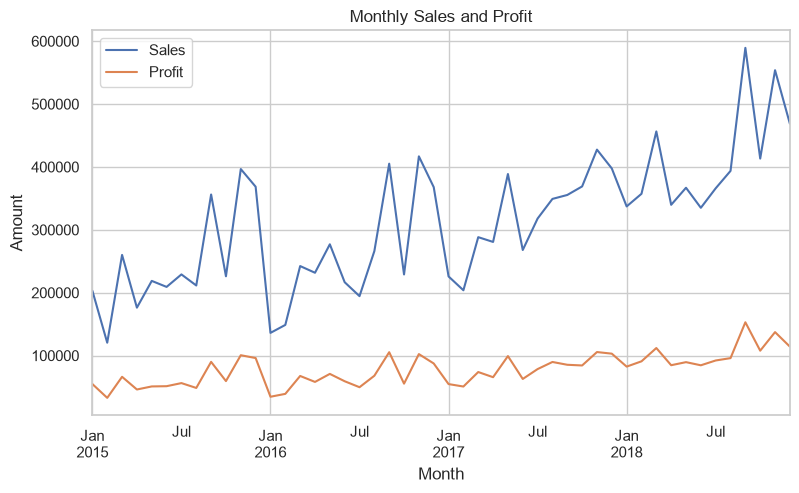

In [10]:
yearly = summarize("Year").sort_index()
yearly["Sales Growth"] = yearly["Sales"].pct_change()
display(yearly)

monthly = df.groupby("Month")[["Sales", "Profit"]].sum()
monthly.index = monthly.index.to_timestamp()
monthly.plot(title="Monthly Sales and Profit")
plt.ylabel("Amount")
plt.show()

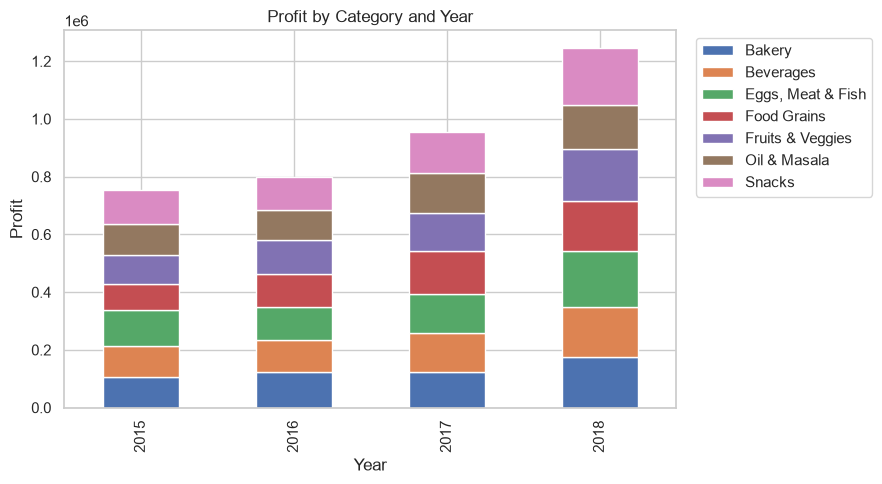

In [11]:
cat_year = df.pivot_table(index="Year", columns="Category", values="Profit", aggfunc="sum")
cat_year.plot(kind="bar", stacked=True, title="Profit by Category and Year")
plt.ylabel("Profit")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

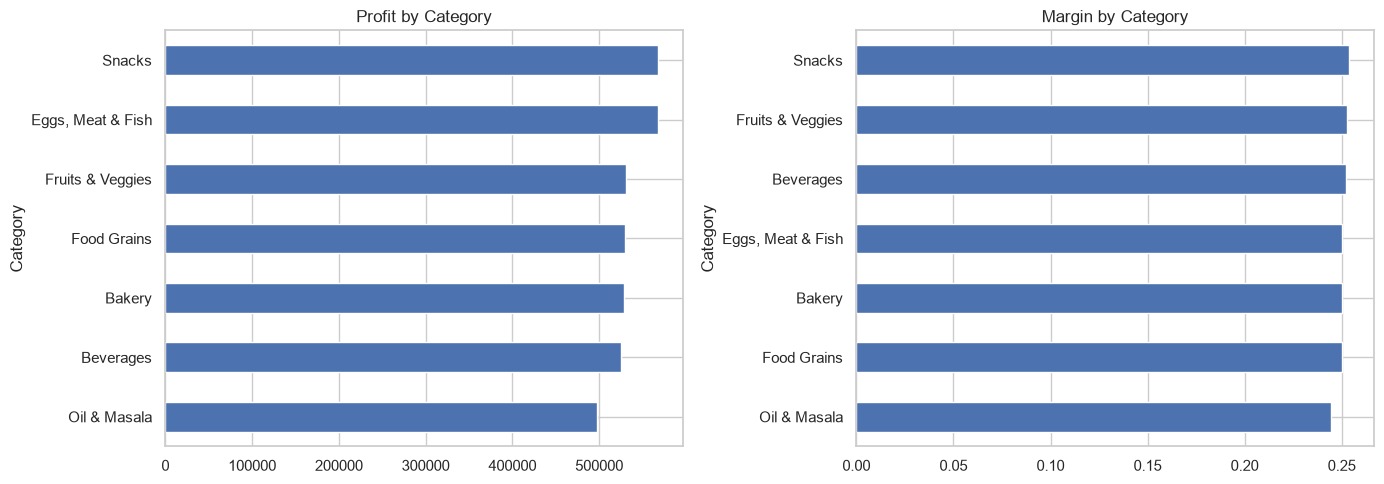

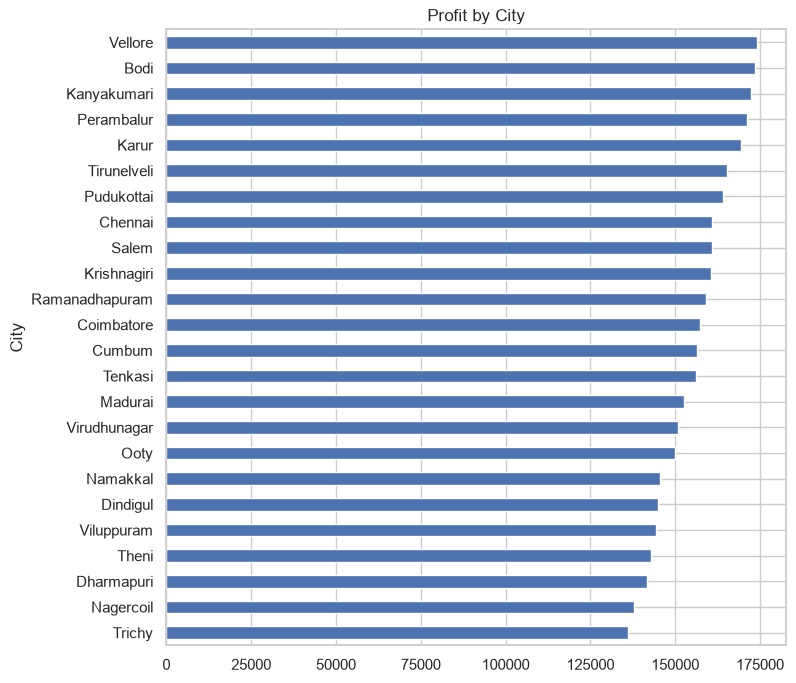

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
by_category["Profit"].sort_values().plot(kind="barh", ax=ax[0], title="Profit by Category")
by_category["Margin"].sort_values().plot(kind="barh", ax=ax[1], title="Margin by Category")
plt.tight_layout()
plt.show()

by_city["Profit"].sort_values().plot(kind="barh", figsize=(8, 8), title="Profit by City")
plt.show()

In [13]:
df[["Sales", "Discount", "Profit", "Margin"]].corr()

,Sales,Discount,Profit,Margin
Sales,1.00,-0.01,0.61,0.01
Discount,-0.01,1.00,0.00,0.01
Profit,0.61,0.00,1.00,0.75
Margin,0.01,0.01,0.75,1.00


,Orders,Sales,Profit,AvgProfit,Margin
DiscountBand,,,,,
10-15%,2207,3301810,"826,969.55",374.70,0.25
15-20%,1875,2816273,"699,520.53",373.08,0.25
20-25%,2012,3021719,"751,465.26",373.49,0.25
25-30%,1944,2886012,"738,819.64",380.05,0.26
30-35%,1956,2931168,"730,346.22",373.39,0.25


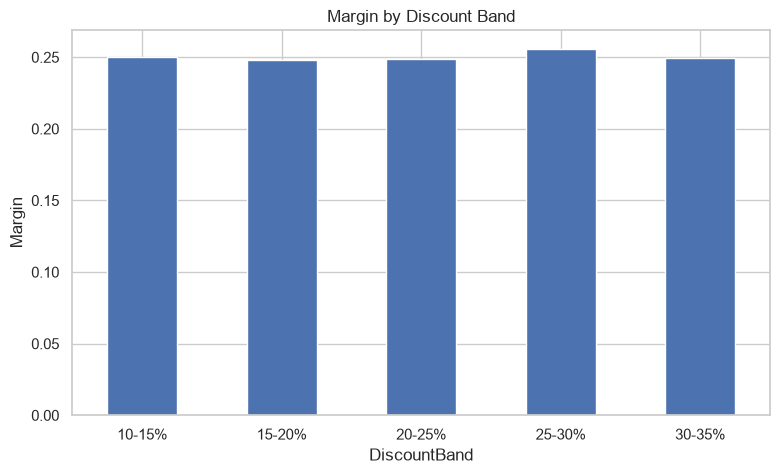

In [14]:
df["DiscountBand"] = pd.cut(
    df["Discount"],
    bins=[0.09, 0.15, 0.20, 0.25, 0.30, 0.35],
    labels=["10-15%", "15-20%", "20-25%", "25-30%", "30-35%"],
)
by_band = df.groupby("DiscountBand", observed=True).agg(
    Orders=("Order ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    AvgProfit=("Profit", "mean"),
)
by_band["Margin"] = by_band["Profit"] / by_band["Sales"]
display(by_band)

by_band["Margin"].plot(kind="bar", title="Margin by Discount Band", rot=0)
plt.ylabel("Margin")
plt.show()

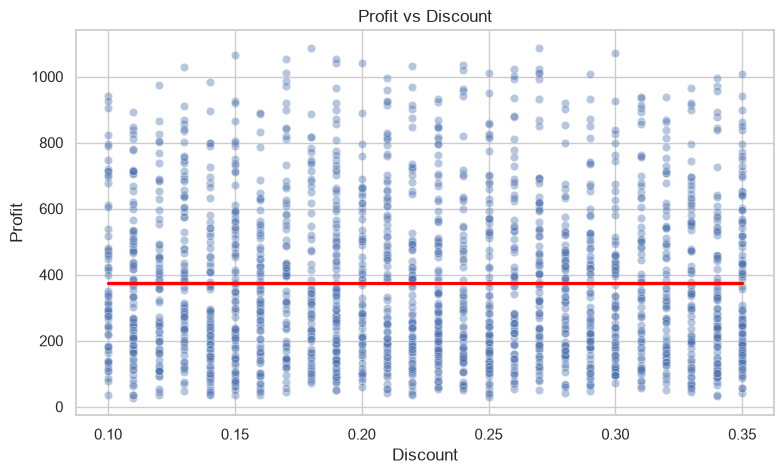

In [15]:
sns.scatterplot(data=df.sample(2000, random_state=1), x="Discount", y="Profit", alpha=0.4)
sns.regplot(data=df, x="Discount", y="Profit", scatter=False, color="red")
plt.title("Profit vs Discount")
plt.show()

In [16]:
# Model:    Profit_i = b0 + b1*Discount_i + b2*Sales_i + e_i
# Estimate: beta_hat = (X'X)^(-1) X'y
# Variance: Var(beta_hat) = sigma2 * (X'X)^(-1),  sigma2 = RSS / (n - k)
# t-stat:   t_j = beta_j / SE_j
# R^2:      1 - RSS/TSS
from scipy import stats

y = df["Profit"].to_numpy()
X = np.column_stack([np.ones(len(df)), df["Discount"], df["Sales"]])
names = ["Intercept", "Discount", "Sales"]

n, k = X.shape
beta = np.linalg.inv(X.T @ X) @ X.T @ y
resid = y - X @ beta
rss = resid @ resid
tss = ((y - y.mean()) ** 2).sum()
sigma2 = rss / (n - k)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
t = beta / se
p = 2 * (1 - stats.t.cdf(np.abs(t), df=n - k))

results = pd.DataFrame({"coef": beta, "std err": se, "t": t, "p-value": p}, index=names)
display(results)
print(f"R-squared = 1 - {rss:,.0f} / {tss:,.0f} = {1 - rss / tss:.4f}")

,coef,std err,t,p-value
Intercept,-3.88,7.89,-0.49,0.62
Discount,10.78,25.60,0.42,0.67
Sales,0.25,0.00,76.02,0.00


R-squared = 1 - 364,460,737 / 575,274,901 = 0.3665


In [17]:
import statsmodels.formula.api as smf

model = smf.ols("Profit ~ Discount + Sales", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.366
Model:                            OLS   Adj. R-squared:                  0.366
Method:                 Least Squares   F-statistic:                     2890.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:47:32   Log-Likelihood:                -66670.
No. Observations:                9994   AIC:                         1.333e+05
Df Residuals:                    9991   BIC:                         1.334e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.8804      7.886     -0.492      0.6

In [18]:
cust = df.groupby("Customer Name").agg(
    Orders=("Order ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    AvgDiscount=("Discount", "mean"),
    LastOrder=("Order Date", "max"),
)
cust["Margin"] = cust["Profit"] / cust["Sales"]
cust.sort_values("Profit", ascending=False).head(10)

,Orders,Sales,Profit,AvgDiscount,LastOrder,Margin
Customer Name,,,,,,
Arutra,218,325720,"87,572.40",0.22,2018-12-26,0.27
Vidya,215,321798,"86,725.64",0.22,2018-12-28,0.27
Krithika,224,334361,"85,633.03",0.22,2018-12-28,0.26
Akash,196,307488,"82,121.26",0.23,2018-12-28,0.27
Surya,209,312645,"80,996.85",0.22,2018-12-29,0.26
Amrish,227,333351,"80,191.89",0.23,2018-12-27,0.24
Vinne,203,319565,"79,873.12",0.23,2018-12-26,0.25
Amy,196,301558,"79,159.94",0.23,2018-12-28,0.26
Harish,208,293839,"79,107.83",0.22,2018-12-23,0.27


Top 10 of 50 customers produce 21.9% of profit


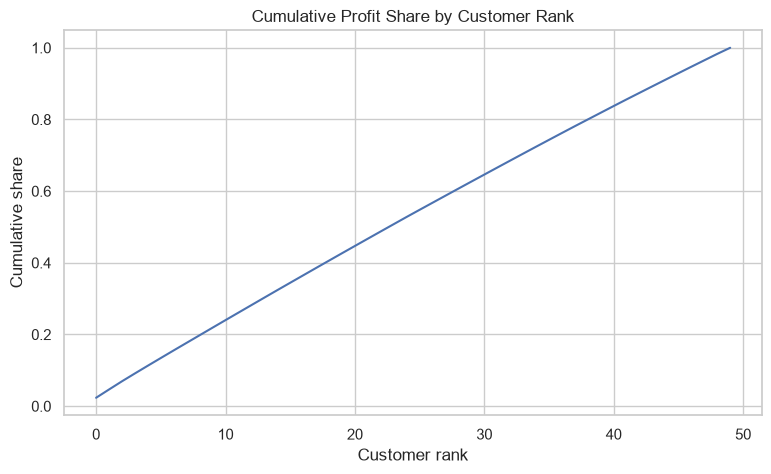

In [19]:
# Share_top_m = sum of top-m customer profits / total profit
sorted_profit = cust["Profit"].sort_values(ascending=False)
share = sorted_profit.cumsum() / sorted_profit.sum()
print(f"Top 10 of {len(cust)} customers produce {share.iloc[9]:.1%} of profit")

share.reset_index(drop=True).plot(title="Cumulative Profit Share by Customer Rank")
plt.xlabel("Customer rank")
plt.ylabel("Cumulative share")
plt.show()

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

feats = cust[["Orders", "Sales", "Margin", "AvgDiscount"]]
scaled = StandardScaler().fit_transform(feats)
cust["Segment"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(scaled)
cust.groupby("Segment")[["Orders", "Sales", "Profit", "Margin", "AvgDiscount"]].mean()

C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Orders,Sales,Profit,Margin,AvgDiscount
Segment,,,,,
0,188.29,"282,620.00","71,407.55",0.25,0.23
1,204.80,"307,297.30","74,735.76",0.24,0.23
2,207.46,"308,192.00","79,882.90",0.26,0.22


MAE = 160.88
R-squared (test) = 0.321


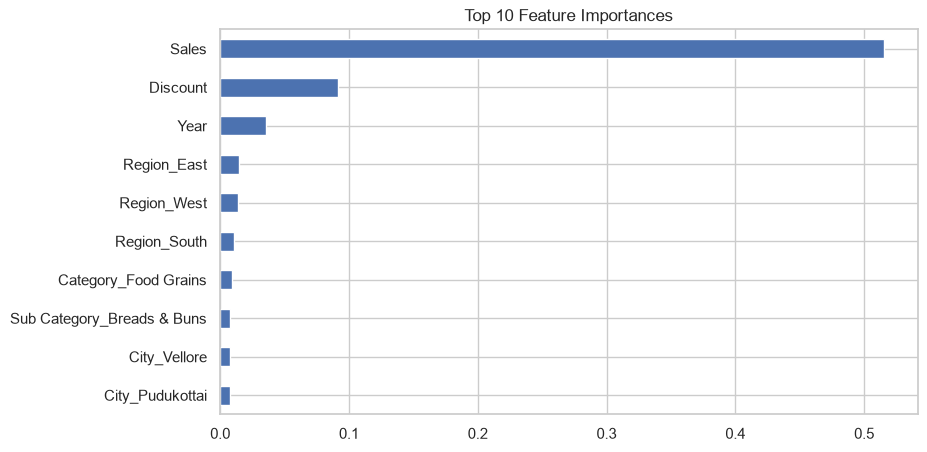

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

features = ["Category", "Sub Category", "City", "Region", "Sales", "Discount", "Year"]
X_all = pd.get_dummies(df[features], drop_first=True)
y_all = df["Profit"]

X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
pred = rf.predict(X_te)

print(f"MAE = {mean_absolute_error(y_te, pred):,.2f}")
print(f"R-squared (test) = {r2_score(y_te, pred):.3f}")

imp = pd.Series(rf.feature_importances_, index=X_all.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind="barh", title="Top 10 Feature Importances")
plt.show()

In [22]:
output_dir = project_root / "notebooks"
df.to_csv(output_dir / "supermarket_clean.csv", index=False)
with pd.ExcelWriter(output_dir / "supermarket_summary.xlsx") as xl:
    by_category.to_excel(xl, sheet_name="Category")
    by_subcat.to_excel(xl, sheet_name="SubCategory")
    by_city.to_excel(xl, sheet_name="City")
    yearly.to_excel(xl, sheet_name="Year")
    by_band.to_excel(xl, sheet_name="DiscountBand")
    cust.to_excel(xl, sheet_name="Customers")
print("Saved supermarket_clean.csv and supermarket_summary.xlsx")

Saved supermarket_clean.csv and supermarket_summary.xlsx


## 13. Final answers

**Business question:** Do discounts make the supermarket more money, and where should it focus?

### 1. Overall performance
$$\text{Overall Margin} = \frac{\sum \text{Profit}}{\sum \text{Sales}} = \frac{3{,}747{,}121}{14{,}956{,}982} = 25.05\%$$

### 2. Categories
- **Most profitable category:** Snacks (profit 568,179, margin 25.4%).
- **Lowest-margin category:** Oil & Masala (margin 24.4%, profit 497,895).
- **Lowest-margin sub-category:** Spices (23.8%). **Highest:** Noodles (26.3%).
- All categories sit between 24.4% and 25.4%, so the differences are small.

### 3. Discount effect (the main economics result)
$$\widehat{\text{Profit}} = -3.88 + 10.78\,\text{Discount} + 0.25\,\text{Sales}$$

- $\hat\beta_1 = 10.78$, $p = 0.67$, so discount has **no statistically significant effect** on profit.
- Correlation of Discount with Profit is 0.000. Correlation of Sales with Profit is 0.605.
- Profit depends on order size: each extra unit of sales adds about 0.25 of profit.

### 4. Discount bands
Margin is about 25% in every band from 10–35% (range 25.0%–25.6%). Giving a 35% discount costs no more margin than giving 10%.

### 5. Growth
Sales grew 5% (2016), 24% (2017) and 29% (2018), with margin steady at 25%. Growth came from more orders, not higher margins.

### 6. Customers
The top 10 of 50 customers produce 21.9% of profit, so there is no heavy dependence on a few buyers.

### 7. Data limitations
- `Region` is unreliable: North has only 1 order, and one city appears under 5 regions.
- Dash-format dates were assumed to be day-first.
- Sales, Discount and Margin are evenly spread (uniform-like), which suggests synthetic data. Real retail data is usually less uniform.
- The Random Forest test $R^2 \approx 0.32$, so the model is weak.

### 8. Recommendation
In this data, discounts do not change profit, so the discount range (10–35%) cannot be justified as a profit driver. If the real business behaves the same way, deep discounts add cost without extra profit, and a smaller discount range should be tested. The stronger lever is **order size**, so promotions that increase basket value (bundles, minimum-spend offers) should be explored. Treat this as a hypothesis to test with real data, not a proven conclusion, because the data looks synthetic.